# EMQA_L1_cy_generation

**Case study: Romanian hydro, nuclear and solar output, current vs previous year**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_cy_generation/EMQA_L1_cy_generation.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Monthly mean Romanian hydro, nuclear and solar generation (GW, reported hours) in the previous year and in the current year to the cut-off: the Cernavoda nuclear plant offline twice and hydro below the previous year; months without reported data stay empty.

**Data:** monthly means of reported hours, 2025-01 to 2026-10. **Source:** energy-charts.info (Fraunhofer ISE); ENTSO-E (Transelectrica data for Romania).

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
MON1 = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Data
Real series from the course repository (see `data/SOURCES.md`), cut at the last complete month; missing values stay missing.

In [3]:
# data cut-off: last complete calendar month common to the Romanian prices and the generation data
_p = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')['RO']
_g = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'hydro_run_of_river'],
                 parse_dates=['date_cet']).set_index('date_cet')['hydro_run_of_river']
_last = min(_p.dropna().index.max(), _g.dropna().index.max())
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_UTC = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')   # end of the CET day, in UTC
Y = END.year
print('data cut-off:', END.date())

# Romanian generation by source and load, hourly mean MW (UTC, interval start)
GH = pd.read_csv(DATA + 'generation_ro_mw_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
GH = GH.loc[GH.index < END_UTC]
# Romanian generation by source, daily mean MW (CET day)
G = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet').loc[:END]

data cut-off: 2026-10-31


## Computation

In [4]:
def lfl_block(cols, y0, y1):
    """Jan..cut-off month of y1 vs the same months of y0, over the hours reported in BOTH years (TWh)."""
    s = GH[cols].sum(axis=1, min_count=len(cols))
    a = s[(s.index.year == y1) & (s.index.month <= END.month)]
    b_ = s[(s.index.year == y0) & (s.index.month <= END.month)]
    A = pd.Series(a.values, index=a.index.strftime('%m-%d %H'))
    B = pd.Series(b_.values, index=b_.index.strftime('%m-%d %H'))
    A, B = A[~A.index.duplicated()], B[~B.index.duplicated()]
    both = pd.concat([A.rename('a'), B.rename('b')], axis=1).dropna()
    return {'ytd': fl(both['a'].sum() / 1e6, 2), 'prev': fl(both['b'].sum() / 1e6, 2),
            'chg': fl((both['a'].sum() / both['b'].sum() - 1) * 100, 1), 'ytd_own': fl(A.sum() / 1e6, 2)}

hm_ = (G['hydro_run_of_river'] + G['hydro_water_reservoir']).resample('MS').mean()    # daily data, monthly mean MW
cmp_ = {m: (hm_.loc[f'{Y}-{m:02d}'].iloc[0], hm_.loc[f'{Y - 1}-{m:02d}'].iloc[0]) for m in range(1, END.month + 1)}
gm = G.loc[f'{Y}-05', 'nuclear']
show('mix.lfl.Nuclear.chg', f'nuclear, Jan-{MON_EN[END.month - 1]} {Y} vs {Y - 1} (hours reported in both), %',
     lfl_block(['nuclear'], Y - 1, Y)['chg'])
show('mix.lfl.Solar.chg', f'solar, Jan-{MON_EN[END.month - 1]} {Y} vs {Y - 1}, %', lfl_block(['solar'], Y - 1, Y)['chg'])
show('nuclear.may_zero_days', f'days in May {Y} with zero nuclear output', int((gm < 1).sum()))
show('nuclear.hydro_aug_oct_chg', f'hydro Aug-{MON_EN[END.month - 1]} {Y} vs {Y - 1}, %',
     fl((sum(cmp_[m][0] for m in range(8, END.month + 1)) / sum(cmp_[m][1] for m in range(8, END.month + 1)) - 1) * 100, 1))

nuclear, Jan-Oct 2026 vs 2025 (hours reported in both), % = -31.3   [mix.lfl.Nuclear.chg]


solar, Jan-Oct 2026 vs 2025, % = 71.2   [mix.lfl.Solar.chg]
days in May 2026 with zero nuclear output = 19   [nuclear.may_zero_days]
hydro Aug-Oct 2026 vs 2025, % = -14.7   [nuclear.hydro_aug_oct_chg]


## Chart

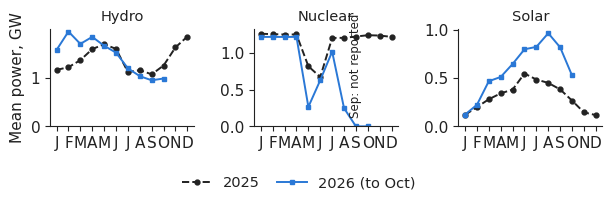

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(6.4, 2.1))
for ax, (ttl, cols) in zip(axs, [('Hydro', ['hydro_run_of_river', 'hydro_water_reservoir']), ('Nuclear', ['nuclear']),
                                 ('Solar', ['solar'])]):
    a = GH.loc[str(Y - 1), cols].sum(axis=1, min_count=len(cols))
    c = GH.loc[str(Y), cols].sum(axis=1, min_count=len(cols))
    ma, mc = a.groupby(a.index.month).mean() / 1000, c.groupby(c.index.month).mean() / 1000
    ax.plot(ma.index, ma.values, color='#222222', ls='--', marker='o', ms=3.5, label=str(Y - 1))
    ax.plot(mc.index, mc.values, color=PAL['RO'], marker='s', ms=3.5, label=f'{Y} (to {MON_EN[END.month - 1]})')
    ax.set_title(ttl, fontsize=10.5)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MON1)
    ax.set_ylim(bottom=0)
axs[1].annotate('Sep: not reported', (9, 0.12), ha='center', fontsize=8.5, rotation=90, va='bottom')
axs[0].set_ylabel('Mean power, GW')
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.17, 1, 1))
plt.savefig('cy_generation.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()